# mPD4_SN | Figure 3

Saved SHINE results. Training seed 123; K=11; clustering seed 123.

Five-fit summaries use seeds 0, 1, 2, 123 and 1234. See [setup and data requirements](README.md).

Inputs: original SMA author pairing, restricted to the frozen common paired cohort. Registration precedes SHINE training.


In [49]:
import os
for key in ("OMP_NUM_THREADS", "OPENBLAS_NUM_THREADS", "MKL_NUM_THREADS", "NUMBA_NUM_THREADS", "VECLIB_MAXIMUM_THREADS"):
    os.environ[key] = "1"
os.environ.setdefault("LOKY_MAX_CPU_COUNT", "1")
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
import shine
from shine import SHINE, normalize_counts
from shine.study import Section

CASE = "mPD4_SN"
# Extract the figure-data archive into data/, or set SHINE_DATA_ROOT.
search_roots = [Path.cwd(), *Path.cwd().parents]
if os.environ.get("SHINE_DATA_ROOT"):
    ROOT = Path(os.environ["SHINE_DATA_ROOT"]).expanduser().resolve()
else:
    ROOT = next((candidate for parent in search_roots
                 for candidate in (parent / "data", parent)
                 if (candidate / "revision_experiments").is_dir()), None)
if ROOT is None:
    raise FileNotFoundError("Extract the figure-data archive into data/, or set SHINE_DATA_ROOT. See data/README.md.")
manifest_candidates = [p / name for p in search_roots
                       for name in ("sections.json", "notebooks/sections.json")]
manifest_candidates.append(ROOT / "SHINE-github/notebooks/sections.json")
MANIFEST = next((p for p in manifest_candidates if p.is_file()), None)
if MANIFEST is None:
    raise FileNotFoundError("Cannot find notebooks/sections.json.")
import sys
sys.path.insert(0, str(MANIFEST.parent))
from figure_plotting import spatial_results, regional_results, molecular_maps, attention_plot, save_panel

OUT = ROOT / "outputs/notebook_results_release_011_20261127" / CASE
OUT.mkdir(parents=True, exist_ok=True)
section = Section(ROOT, MANIFEST, CASE)
print("shine-omics", shine.__version__, "|", CASE, "|", len(section.spots), "paired spots")

shine-omics 0.1.1 | mPD4_SN | 3021 paired spots


## 1. Settings

Fixed figure settings and paired cohort. Source files are verified by SHA-256.

In [50]:
settings = {"Figure": section.config["figure"], "K": section.config["K"],
            "epochs": 120, "training_seed": 123,
            "clustering_seed": section.config["display_clustering_seed"],
            "local_mask": True, "local_neighbors": section.config["graph_options"]["local_k"],
            "spatial_graph_neighbors": section.config["graph_options"]["spatial_k"], "final_ReLU": True, **section.config["model_options"]}
display(pd.Series(settings, name="Final setting").to_frame())
display(section.spots.groupby(["region", "lesion"], dropna=False).size().rename("paired_spots").reset_index())

                        Final setting
Figure                              3
K                                  11
epochs                            120
training_seed                     123
clustering_seed                   123
local_mask                       True
local_neighbors                     6
spatial_graph_neighbors             6
final_ReLU                       True
loss                         original
l2                               True
spatial_floor                     0.0
latent_dim                        128
attention_backend              sparse
evaluate_zero_alignment         False

       region    lesion  paired_spots
0     CA1-CA2    intact            49
1     CA1-CA2  lesioned            78
2         CA3    intact            28
3         CA3  lesioned            41
4          DG    intact            39
5          DG  lesioned            48
6         HPF    intact           365
7         HPF  lesioned           352
8   Isocortex    intact            97
9   Isocortex  lesioned           157
10         MB    intact           473
11         MB  lesioned           354
12        PAG    intact            39
13        PAG  lesioned            33
14        SNr    intact           112
15        SNr  lesioned            36
16         TH    intact           100
17         TH  lesioned            70
18    VTA-SNc    intact           112
19    VTA-SNc  lesioned           104
20     fibers    intact            36
21     fibers  lesioned            52
22      ulcer  lesioned            46
23        NaN    intact           107
24        NaN  lesioned            93

## 2. Inputs

These paired matrices are already preprocessed. Do not repeat normalization or registration.

In [51]:
print(section.config["preprocessing"])
input_audit = pd.DataFrame([
    {"modality": name, "spots": x.shape[0], "features": x.shape[1],
     "finite": bool(np.isfinite(x).all()), "constant_rows": int((x.std(1) == 0).sum()),
     "minimum": float(x.min()), "maximum": float(x.max())}
    for name, x in [("RNA", section.rna), ("MSI", section.msi)]])
display(input_audit)
assert section.spots.spot.is_unique
assert np.allclose(section.xy, section.spots[["x", "y"]])
# For raw counts: normalize_counts(full_counts, feature_indices=frozen_columns)
# Do not renormalize section.rna or section.msi.

Frozen author SMA matched cohort. RNA and MSI total/TIC 10000/log1p; frozen 2000 RNA features. Do not refit registration, expand the cohort, or renormalize inputs.npz.


  modality  spots  features  finite  constant_rows  minimum   maximum
0      RNA   3021      2000    True              0      0.0  8.063239
1      MSI   3021      1538    True              0      0.0  7.909461

## 3. Graphs

H5 + H20; spatial kNN6; feature correlation-kNN20; local self+6 attention. Graphs use no annotation labels.

In [52]:
data, graphs = section.prepare()
display(pd.Series(graphs["audit"], name="Graph audit").to_frame())
print("Validated tensor shape:", data.shape)
print("Input + graph fingerprint:", data.fingerprint())

Validated tensor shape: (3021, 2000, 1538)
Input + graph fingerprint: 93f7bd0b85a50a901c7d2af7db8f8464c074b7177c3fc27c7e092349118451a8


                                     Graph audit
n_spots                                     3021
spatial_k                                      6
feature_k                                     20
local_mask                                  True
local_k                                        6
cross_modal_support          self_plus_neighbors
hyperedge_sizes                          [5, 20]
n_hyperedges                                6042
pca_components                                30
pca_seed                                       0
constant_feature_rows                     [0, 0]
allow_constant_feature_rows                 True
labels_used                                False
sparse_propagation                         False

## 4. Model

Replay the saved figure model. Set `RUN_NEW_TRAINING=True` for a separate 120-epoch fit.

In [53]:
model, labels, replay_audit = section.replay(data)
display(pd.Series(replay_audit).to_frame("Replay check"))
RUN_NEW_TRAINING = False
if RUN_NEW_TRAINING:
    new_model = SHINE(**section.config["model_options"])
    def progress(record):
        if record["epoch"] % 20 == 0:
            print("Epoch", record["epoch"], "loss", round(record["total"], 5))
    new_model.fit(data, epochs=120, seed=123, lr=1e-4, weight_decay=1e-3, progress=progress)
    new_labels = new_model.cluster(section.config["K"], seed=section.config["display_clustering_seed"])
    new_model.save(OUT / "new_training_seed123.pt")
    display(section.score(new_labels))
else:
    print("Displaying the saved figure model.")

Displaying the saved figure model.


                                                           Replay check
embedding_max_abs_error                                             0.0
figure_labels_exact                                                True
n_spots                                                            3021
origin                   saved figure checkpoint; new package inference

## 5. ARI and NMI

Average five clustering seeds within each fit, then report mean and sample SD over five training seeds. Regional scores retain whole-section cluster IDs.

In [54]:
display_metrics = section.score(labels)
raw_metrics, per_fit, summary = section.five_fit_metrics()
print("Displayed fit: seed 123")
display(display_metrics.round(4))
print("Five fits: mean and sample SD")
display(summary.round(4))
display(per_fit.round(4))
for name, table in [("display_metrics", display_metrics), ("all_partitions", raw_metrics),
                    ("per_training_fit", per_fit), ("five_fit_summary", summary)]:
    table.to_csv(OUT / (name + ".csv"), index=False)

Displayed fit: seed 123
Five fits: mean and sample SD


        endpoint  n_scored     ARI     NMI
0  Whole section      2821  0.3223  0.4731
1            SNr       148  0.4521  0.5033
2        VTA-SNc       216  0.1825  0.2793

        endpoint  ARI_mean  ARI_std  NMI_mean  NMI_std  n_fits
0            SNr    0.4085   0.0578    0.4624   0.0497       5
1        VTA-SNc    0.1727   0.0192    0.2651   0.0186       5
2  Whole section    0.3221   0.0088    0.4650   0.0118       5

         endpoint  training_seed     ARI     NMI
0             SNr              0  0.3546  0.4128
1             SNr              1  0.3394  0.4060
2             SNr              2  0.4288  0.4819
3             SNr            123  0.4600  0.5127
4             SNr           1234  0.4596  0.4987
5         VTA-SNc              0  0.1679  0.2936
6         VTA-SNc              1  0.2000  0.2647
7         VTA-SNc              2  0.1759  0.2478
8         VTA-SNc            123  0.1735  0.2701
9         VTA-SNc           1234  0.1463  0.2494
10  Whole section              0  0.3229  0.4499
11  Whole section              1  0.3173  0.4633
12  Whole section              2  0.3106  0.4582
13  Whole section            123  0.3265  0.4756
14  Whole section           1234  0.3335  0.4779

## 6. Spatial partition and UMAP

Manuscript colors and spatial rendering; seed 123. Filled display cells remove scatter gaps without changing measured spots or cluster IDs. Grey denotes unlabelled or unpaired tissue. UMAP is used only for visualization.


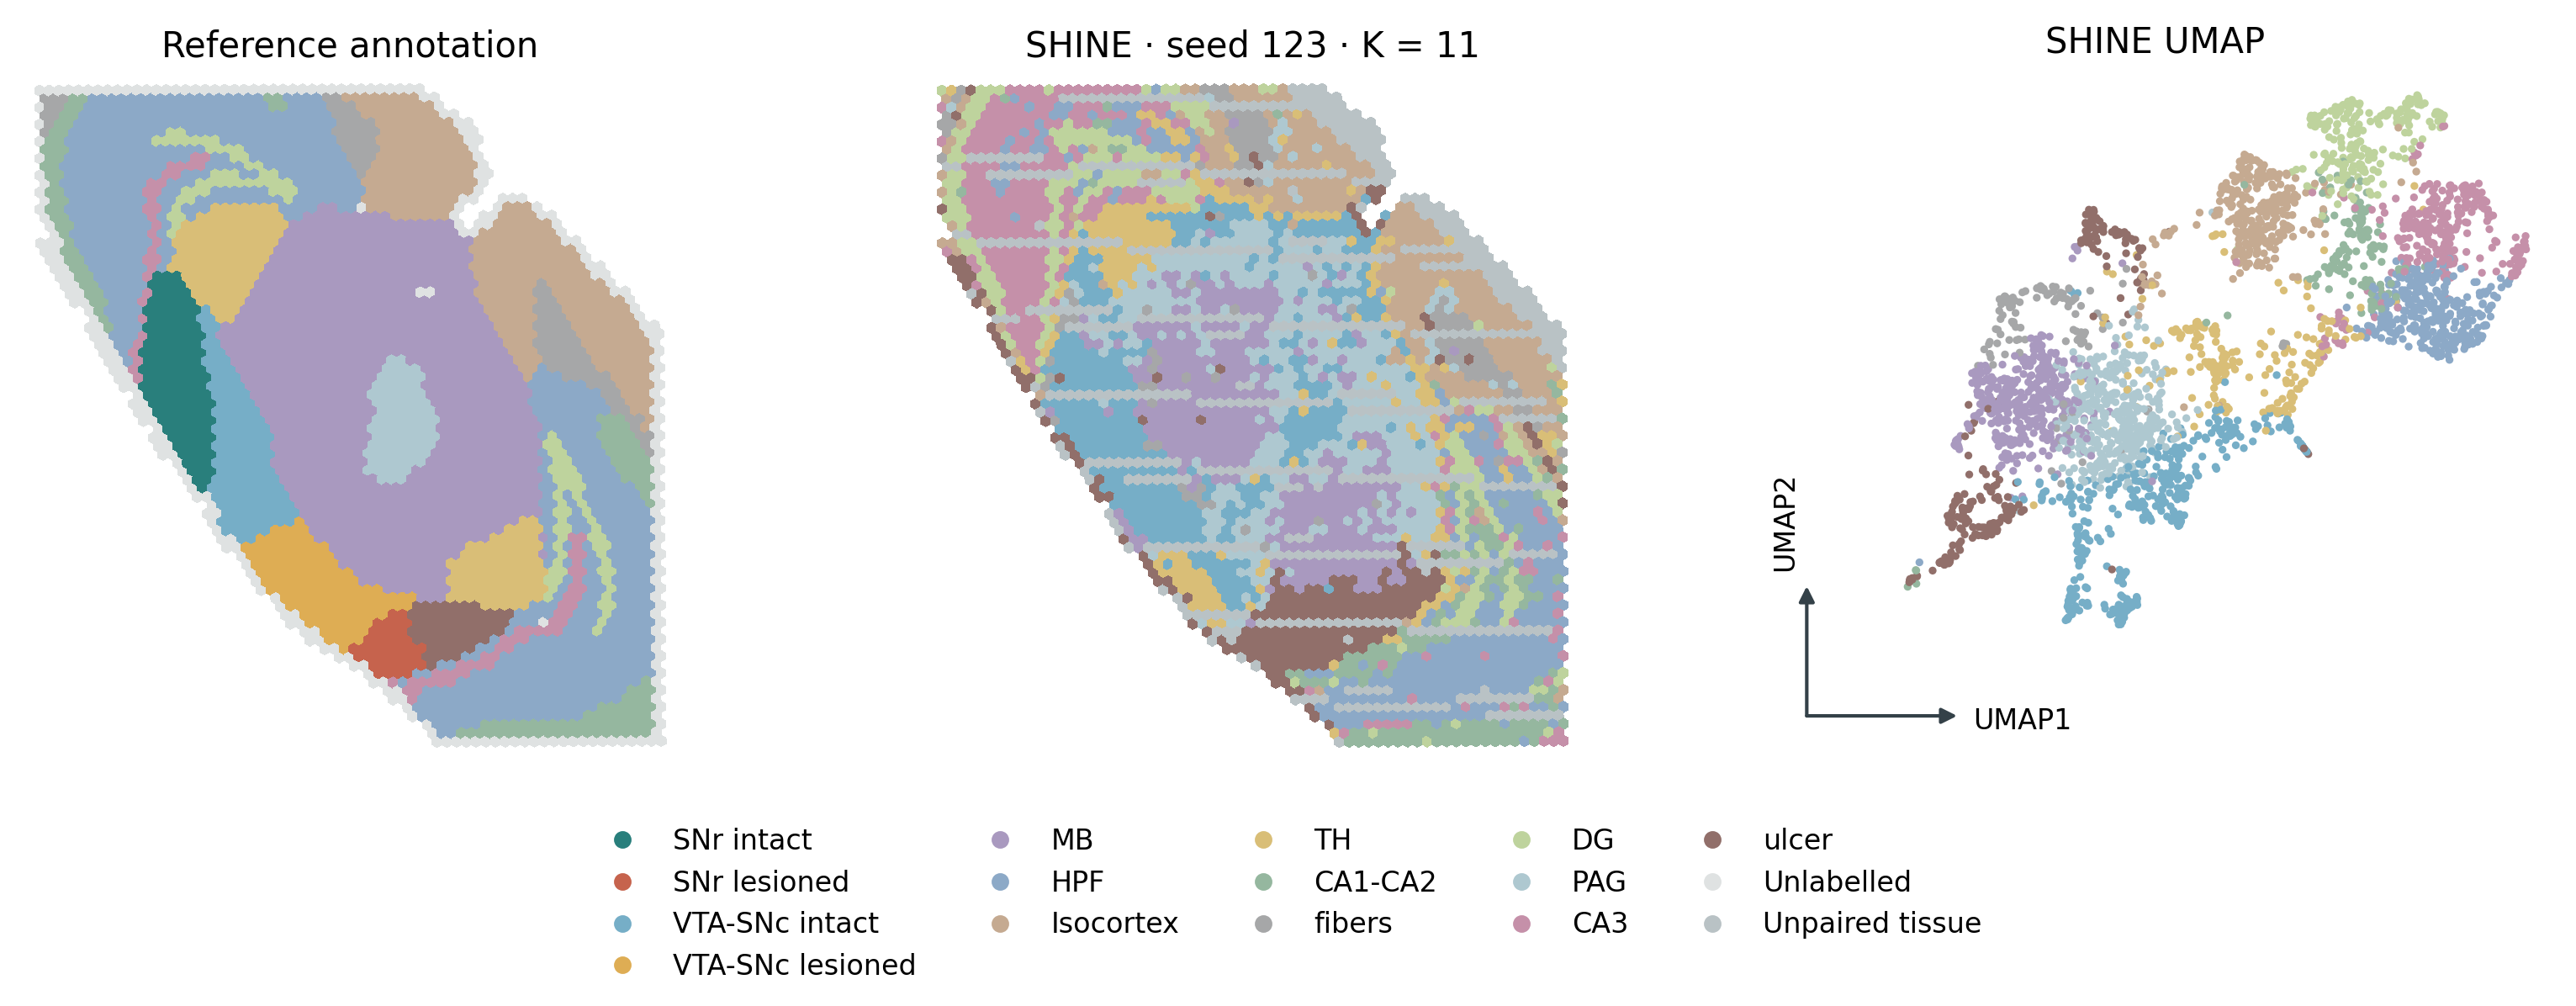

In [55]:
import umap
saved_embedding = np.load(section.path("embedding_123"))
umap_xy = umap.UMAP(n_neighbors=15, min_dist=0.3, random_state=123, n_jobs=1).fit_transform(saved_embedding)
fig = spatial_results(section, labels, umap_xy)
save_panel(fig, OUT / "seed123_spatial_UMAP")
plt.show()
spatial_source = section.spots.copy()
spatial_source["SHINE_cluster"] = labels
spatial_source[["UMAP1", "UMAP2"]] = umap_xy
spatial_source.to_csv(OUT / "seed123_spatial_source.csv", index=False)

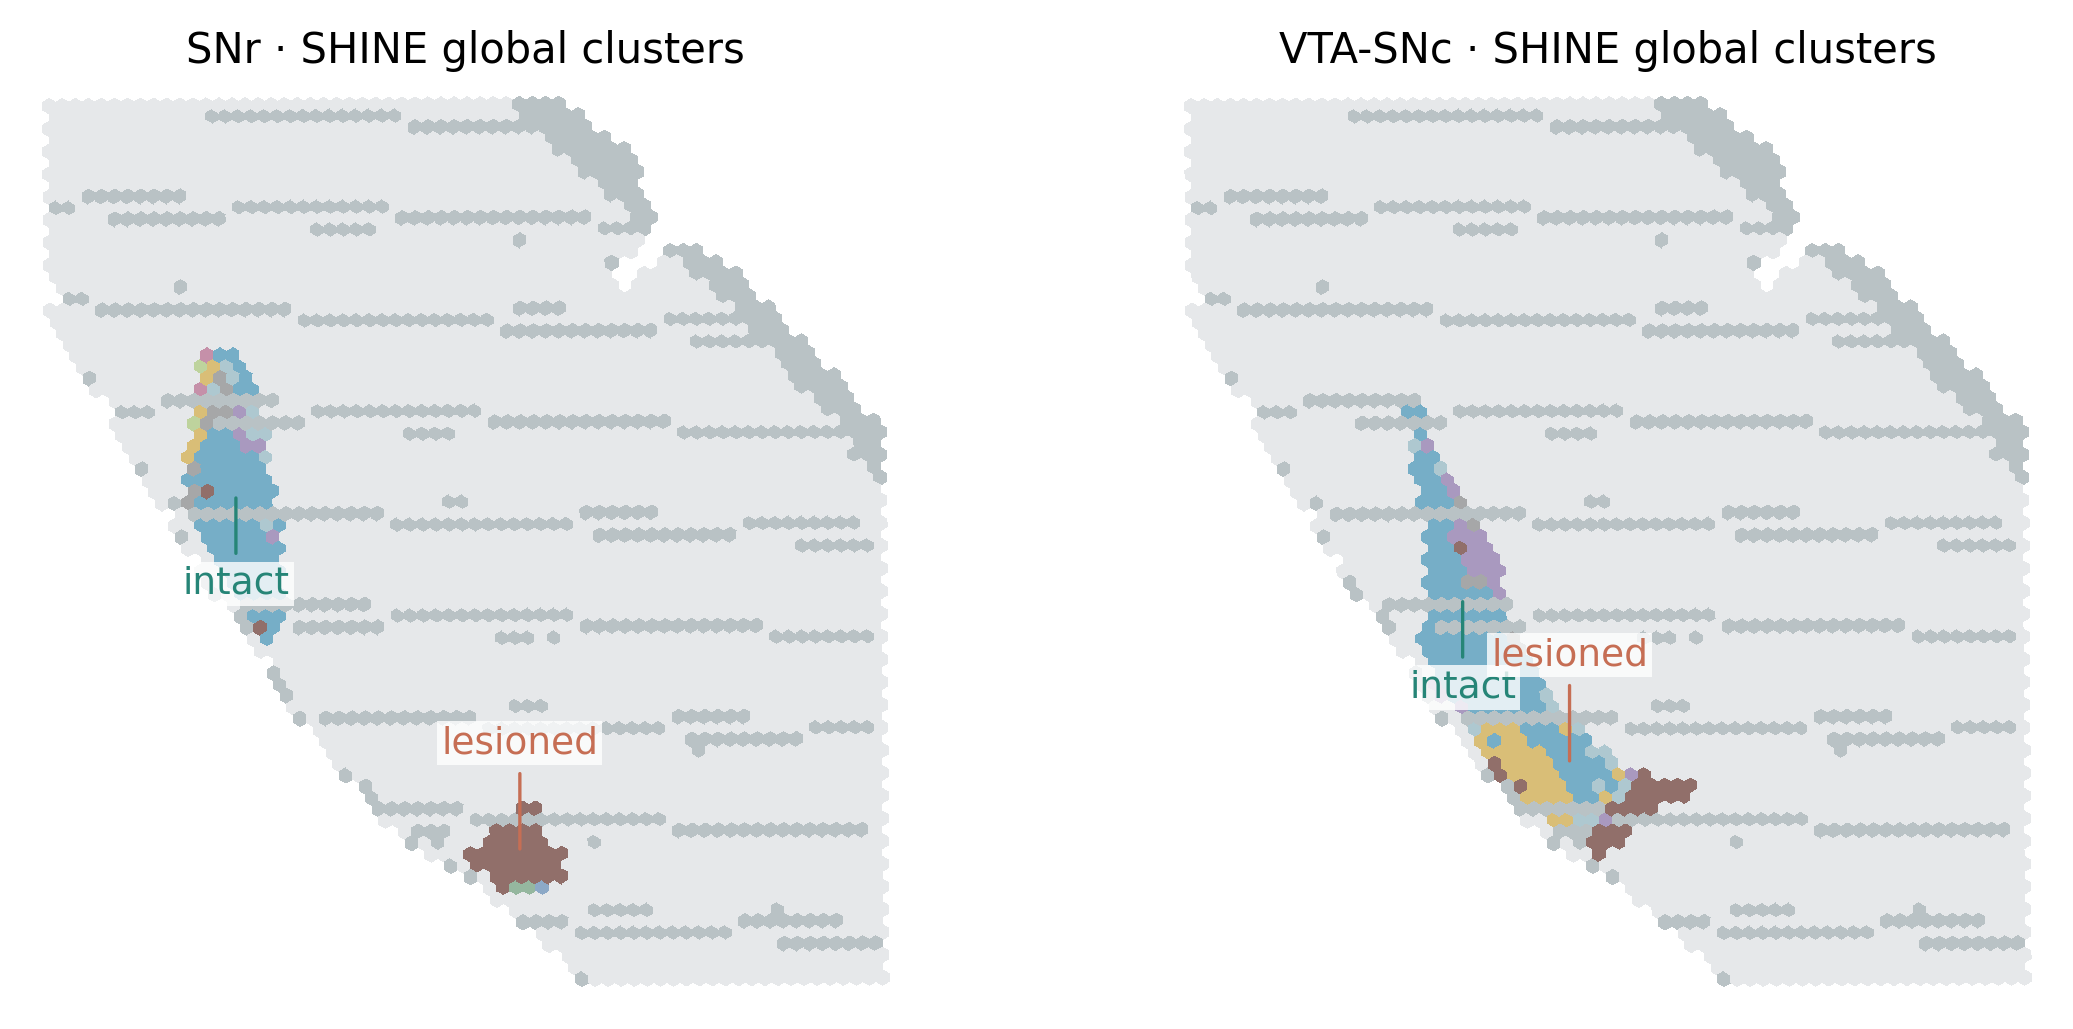

In [56]:
fig = regional_results(section, labels)
save_panel(fig, OUT / "seed123_regions")
plt.show()

## 7. Attention

Spatial-branch weights within RNA and MSI. These are mixing weights, not causal importance.

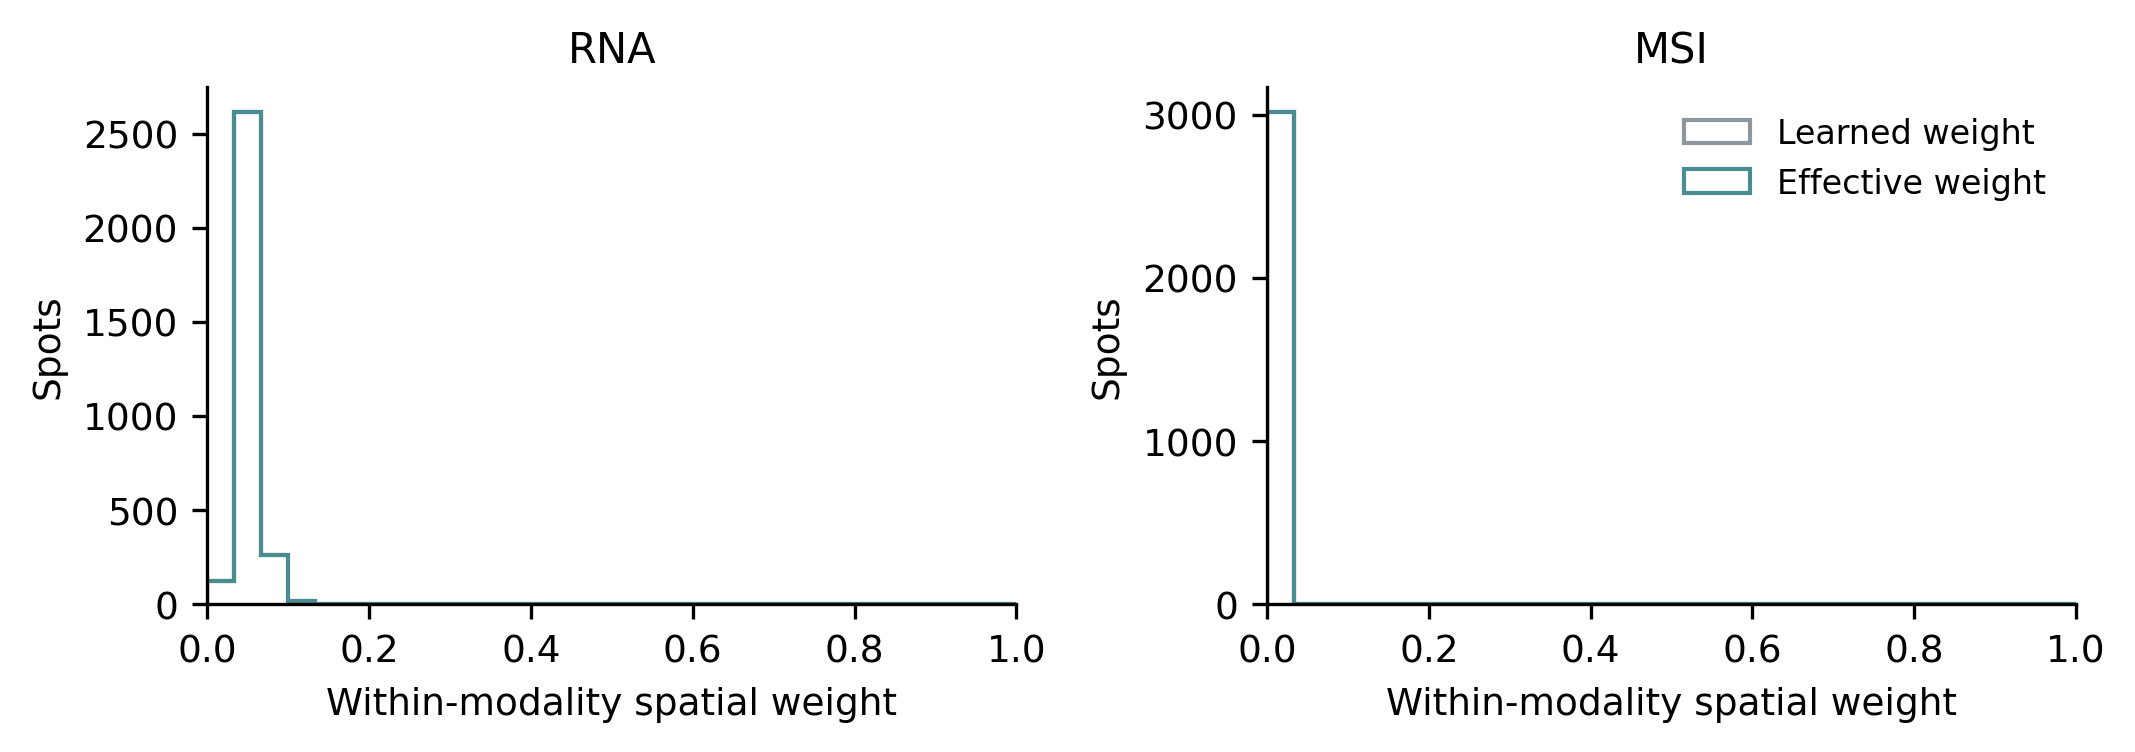

       RNA_spatial_raw  ...  MSI_spatial_effective
count         3021.000  ...               3021.000
mean             0.049  ...                  0.014
std              0.013  ...                  0.002
min              0.026  ...                  0.010
25%              0.040  ...                  0.012
50%              0.046  ...                  0.013
75%              0.055  ...                  0.015
max              0.166  ...                  0.034

[8 rows x 4 columns]

In [57]:
fig = attention_plot(model)
save_panel(fig, OUT / "attention_weights")
plt.show()
attention_source = pd.DataFrame({"spot": section.spots.spot,
    "RNA_spatial_raw": model.attention_["rna_raw"][:, 0],
    "RNA_spatial_effective": model.attention_["rna"][:, 0],
    "MSI_spatial_raw": model.attention_["msi_raw"][:, 0],
    "MSI_spatial_effective": model.attention_["msi"][:, 0]})
attention_source.to_csv(OUT / "attention_source.csv", index=False)
display(attention_source.drop(columns="spot").describe().round(3))

## 8. Measured genes and MSI peaks

Figure 3 markers, compared within SNr and VTA–SNc by anatomical side. MSI labels are measured m/z values.

RNA: ['Th', 'Slc6a3', 'Ddc', 'Slc18a2', 'Aldh1a1', 'Penk', 'Tac1', 'Drd1']
MSI m/z: ['674.2805', '435.20692']


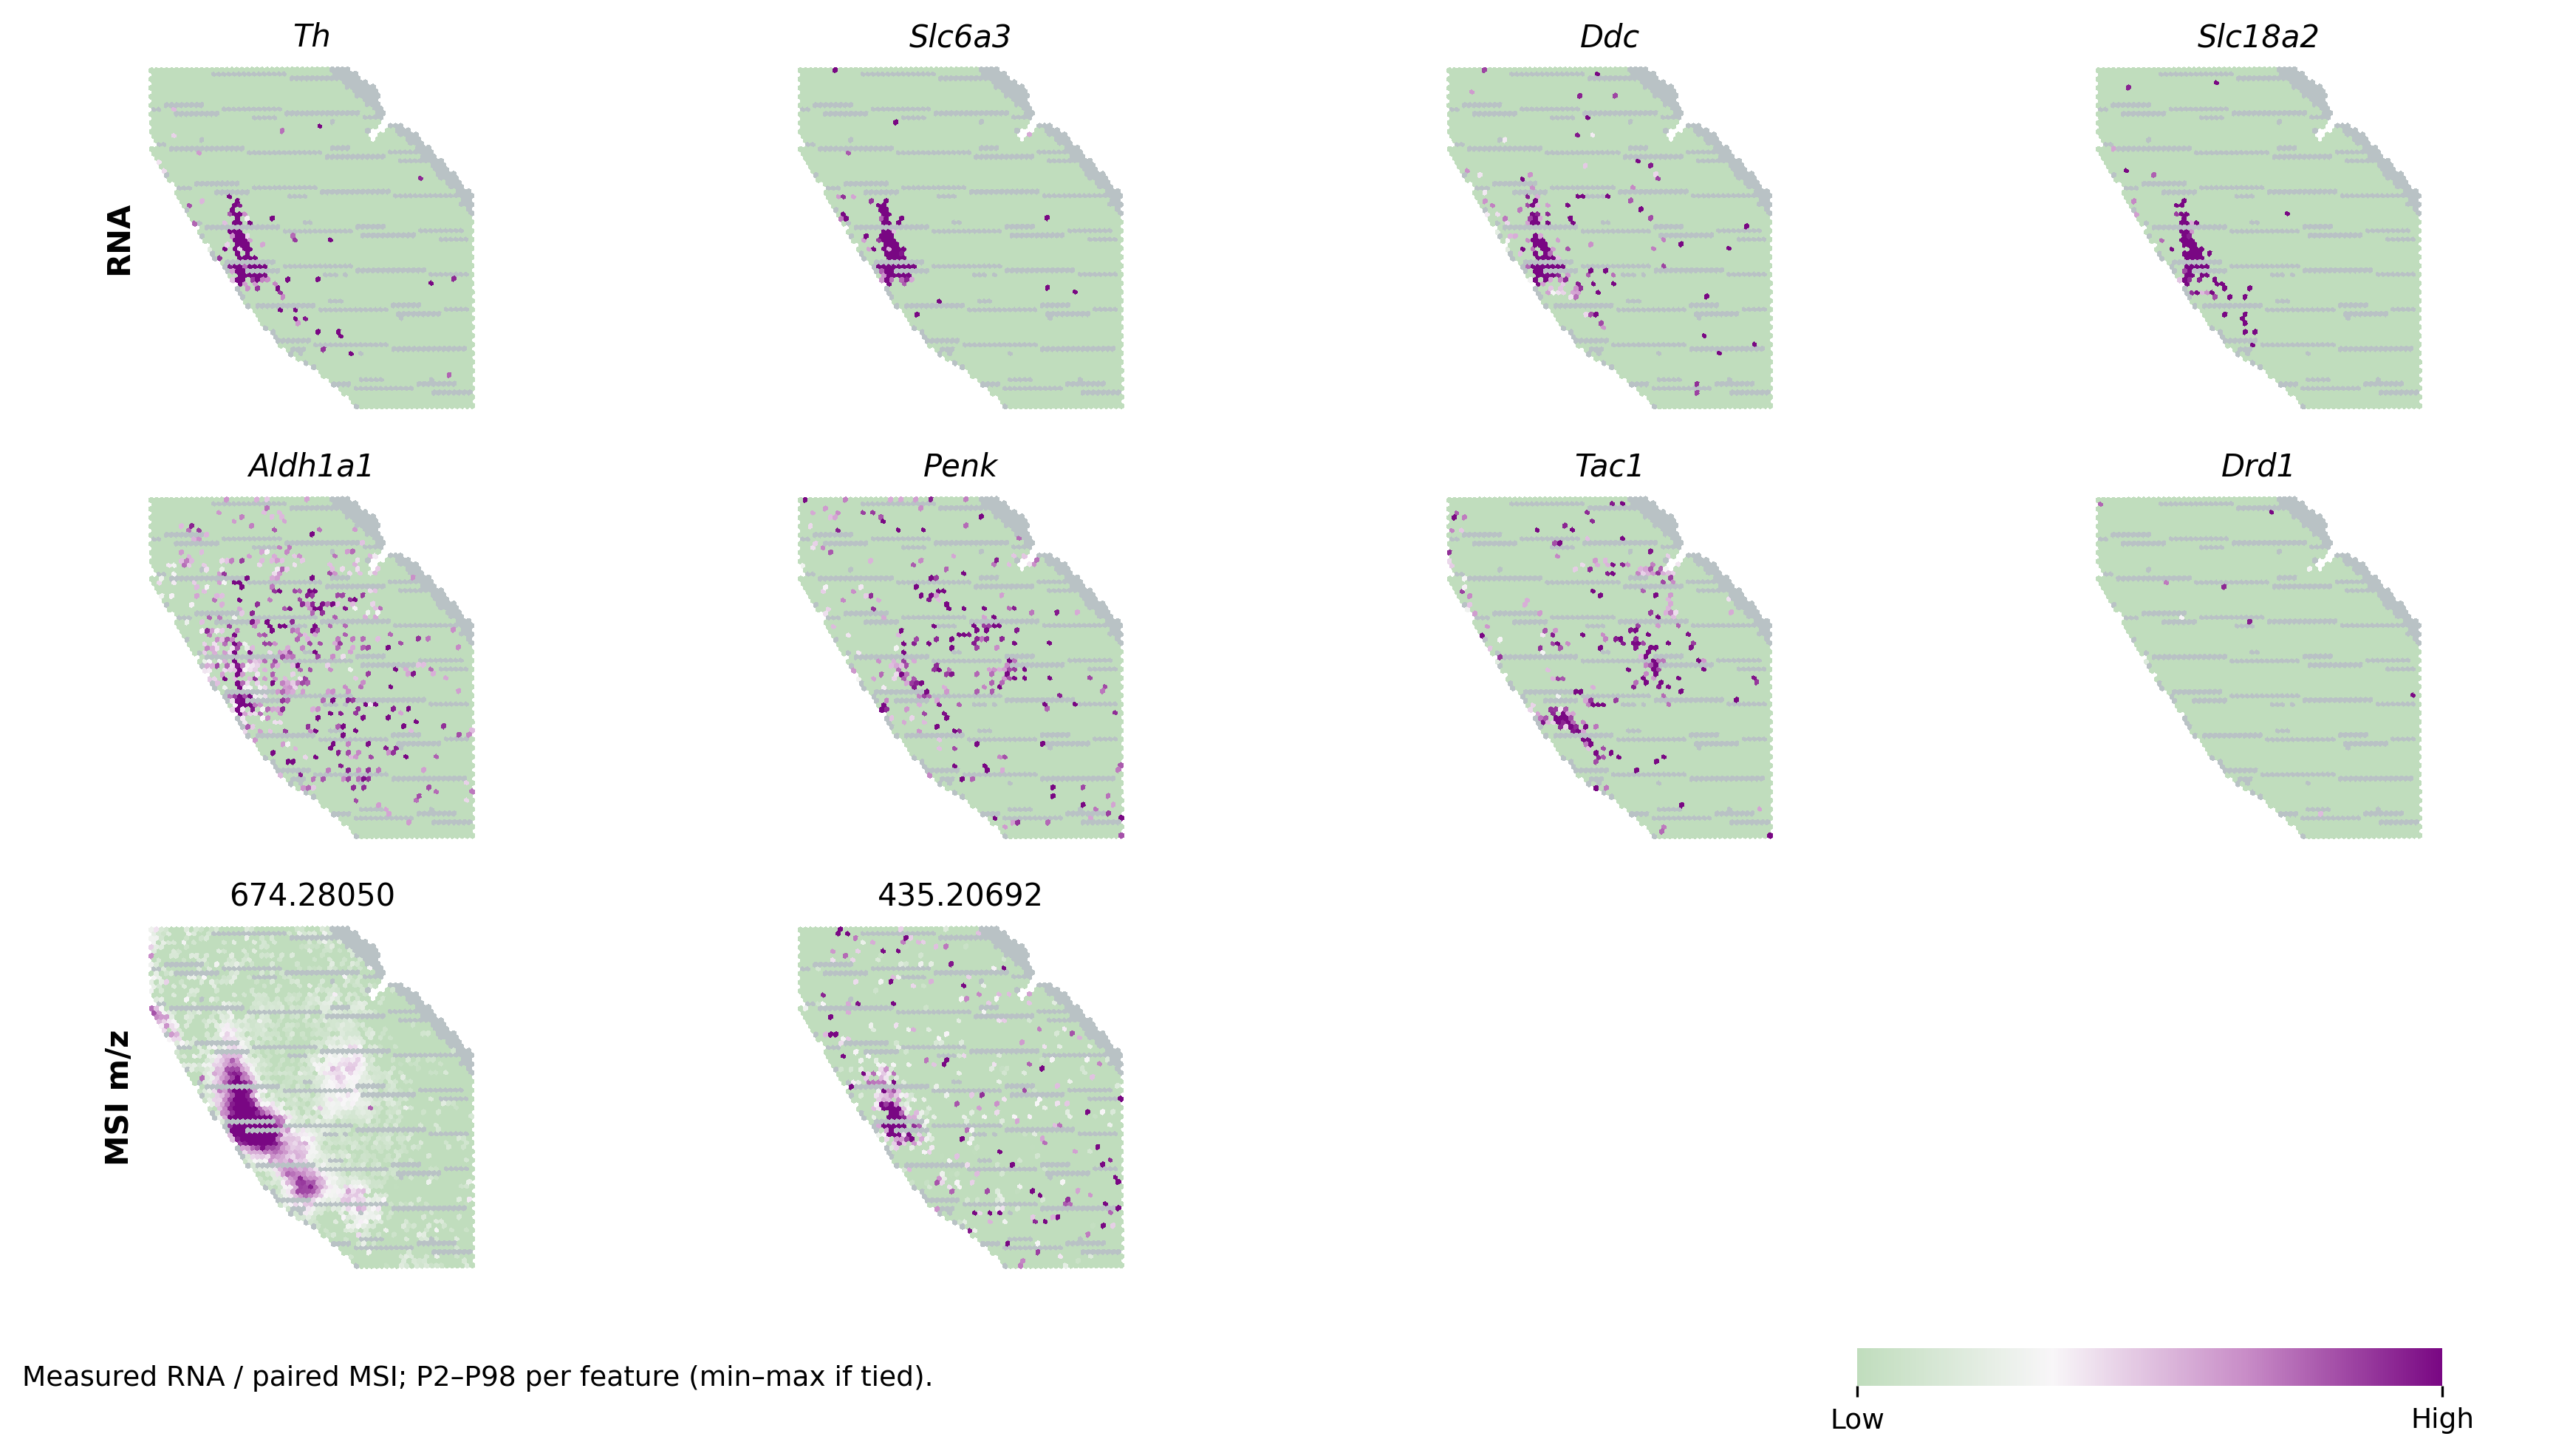

                          contrast    feature  ...  mean_target  difference_SD
0       SNr: lesioned minus intact         Th  ...        0.048         -0.528
1       SNr: lesioned minus intact     Slc6a3  ...        0.000         -0.584
2       SNr: lesioned minus intact        Ddc  ...        0.000         -0.581
3       SNr: lesioned minus intact    Slc18a2  ...        0.000         -0.464
4       SNr: lesioned minus intact    Aldh1a1  ...        0.103         -0.811
5       SNr: lesioned minus intact       Penk  ...        0.111         -0.054
6       SNr: lesioned minus intact       Tac1  ...        0.063          0.190
7       SNr: lesioned minus intact       Drd1  ...        0.000            NaN
8       SNr: lesioned minus intact   674.2805  ...        0.215         -1.307
9       SNr: lesioned minus intact  435.20692  ...        0.048         -0.337
10  VTA-SNc: lesioned minus intact         Th  ...        0.197         -0.674
11  VTA-SNc: lesioned minus intact     Slc6a3  ...  

In [58]:
molecules = section.molecular_values()
print("RNA:", section.config["display_genes"])
print("MSI m/z:", section.config["display_peaks"])
fig = molecular_maps(section, molecules)
save_panel(fig, OUT / "measured_molecules")
plt.show()
measured_source = pd.concat([section.spots[["spot", "x", "y", "region", "lesion"]], molecules], axis=1)
measured_source.to_csv(OUT / "measured_molecule_source.csv", index=False)
effects = section.molecular_comparison(molecules, labels)
display(effects.round(3))
effects.to_csv(OUT / "measured_molecule_effects.csv", index=False)

## 9. RNA–MSI associations

Correlations are calculated separately by region and side. Constant or sparsely detected signals are flagged.

In [59]:
section.verify("molecular_associations")
associations = pd.read_csv(section.path("molecular_associations"))
associations = associations[associations.animal.eq(section.config["animal"])]
display(associations)
associations.to_csv(OUT / "gene_MSI_associations.csv", index=False)

        case animal   region  ... n_estimable_deletions deletion_min  deletion_max
72        C1   mPD4       CP  ...                    32    -0.052332     -0.014207
73        C1   mPD4       CP  ...                    32    -0.057901     -0.007316
74        C1   mPD4       CP  ...                    32    -0.096349     -0.039122
75        C1   mPD4       CP  ...                     0          NaN           NaN
76        C1   mPD4       CP  ...                     0          NaN           NaN
..       ...    ...      ...  ...                   ...          ...           ...
427  mPD4_SN   mPD4  VTA-SNc  ...                     0          NaN           NaN
428  mPD4_SN   mPD4  VTA-SNc  ...                     0          NaN           NaN
429  mPD4_SN   mPD4  VTA-SNc  ...                    13     0.220431      0.300038
430  mPD4_SN   mPD4  VTA-SNc  ...                    13    -0.081635      0.265775
431  mPD4_SN   mPD4  VTA-SNc  ...                    13     0.263352      0.329475

[21

## 10. Validation and exports

Saved-model replay and fresh training are reported separately. Fresh fits do not replace the figure model.

In [60]:
validation_dir = ROOT / "outputs/shine_omics_notebooks_validation_20261124" / CASE
for filename in ["replay_validation.json", "fresh_training_validation.json"]:
    path = validation_dir / filename
    if path.exists():
        display(pd.Series(json.loads(path.read_text()), name=filename).to_frame())
    else:
        print(filename, "Not available; training validation is incomplete.")
fresh_path = validation_dir / "fresh_training_validation.json"
if fresh_path.exists():
    fresh_check = json.loads(fresh_path.read_text())
    if fresh_check["partition_ARI_vs_historical"] < 1.0:
        print("Fresh training changed the KMeans partition despite a small embedding difference. Maps retain the saved figure model.")
        old_scores = pd.read_csv(validation_dir / "display_seed123_metrics.csv")
        new_scores = pd.read_csv(validation_dir / "fresh_seed123_metrics.csv")
        display(old_scores.merge(new_scores, on="endpoint", suffixes=("_figure", "_new_training")).round(4))
        diagnostic_path = validation_dir / "numerical_retraining_diagnostic.json"
        if diagnostic_path.exists():
            diagnostic = json.loads(diagnostic_path.read_text())
            print("Partition agreement with fixed historical centroid initialization:", diagnostic["matched_final_centroids_partition_ARI"],
                  "(numerical diagnostic only; not an independent fit).")
provenance = {"case": CASE, "package_version": shine.__version__, "settings": settings,
              "replay": replay_audit, "sources": section.config["sources"],
              "statistical_unit": "training seed; sample SD over five fits",
              "spatial_train_seed": 123, "new_training_replaces_figure": False}
(OUT / "notebook_provenance.json").write_text(json.dumps(provenance, indent=2))
print("Output directory:", OUT)

Fresh training changed the KMeans partition despite a small embedding difference. Maps retain the saved figure model.
Partition agreement with fixed historical centroid initialization: 1.0 (numerical diagnostic only; not an independent fit).
Output directory: /Users/dubingxue/Desktop/SHINE/outputs/notebook_results_release_011_20261127/mPD4_SN


                                                    replay_validation.json
embedding_max_abs_error                                                0.0
figure_labels_exact                                                   True
n_spots                                                               3021
origin                      saved figure checkpoint; new package inference
graph_audit              {'n_spots': 3021, 'spatial_k': 6, 'feature_k':...
data_fingerprint         93f7bd0b85a50a901c7d2af7db8f8464c074b7177c3fc2...
seconds                                                           61.22775

                                                      fresh_training_validation.json
validation_key                     ae6956ea7f5600ac461c5b3b2265b253b74a65031d2777...
case                                                                         mPD4_SN
epochs                                                                           120
training_seed                                                                    123
seconds                                                                   843.418119
finite_embedding                                                                True
fresh_vs_historical_max_abs_error                                           0.000002
partition_ARI_vs_historical                                                 0.756017
main_figure_overwritten                                                        False

        endpoint  n_scored_figure  ...  ARI_new_training  NMI_new_training
0  Whole section             2821  ...            0.3067            0.4693
1            SNr              148  ...            0.4676            0.5120
2        VTA-SNc              216  ...            0.1845            0.2831

[3 rows x 7 columns]